# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number:**

| Full Name | UNI |
|-----------|-----|
|Xixi PAN   |xp2247|
|Savannah Estridge|sre2129     |

**Public GitHub repository URL:**

## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [ ]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

In [ ]:
# Import dependencies
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
whr_df = pd.read_csv('data/WHR_2023.csv')

# Inspect the first few rows to understand the structure
whr_df

In [ ]:
# Convert the regression target ('happiness_score') into classification labels
# Use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'],
                                       q=5,
                                       labels=['Very Low', 'Low','Average', 'High', 'Very High'])

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

**A:**
1. `y_train.astype('category').cat.codes` coverts the categorical happiness labels into numerical codes.
2. `y_train` contains the original happiness categorical labels: Very Low, Low, Average, High, Very High, while `y_train_labels` contains the corresponding numerical codes.

In [ ]:
# Country development indicators to merge
countrydata=pd.read_csv("data/newcountryvars.csv")

countrydata.head()

Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.

Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.

Hint: Look at the 'how' parameter of the pandas merge function.

Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.

Some country names differ between the two files; you may optionally harmonize them before merging.

In [ ]:
#Some country names differ between the two files; you may optionally harmonize them before merging.
def check_match(df, ref, col='country', ref_col='country_name'):
    common = set(df[col]) & set(ref[ref_col])
    missing = set(df[col]) - set(ref[ref_col])
    print(f"Match: {len(common)}  | Unmatch: {len(missing)} ")
    print("Unmatch:", sorted(missing))
    return missing

missing_train = check_match(X_train, countrydata)
missing_test = check_match(X_test, countrydata)

Match: 89  | Unmatch: 6 
Unmatch: ['Czechia', 'Hong Kong S.A.R. of China', 'North Macedonia', 'Taiwan Province of China', 'Turkiye', 'Vietnam']
Match: 39  | Unmatch: 3 
Unmatch: ['Congo (Brazzaville)', 'Congo (Kinshasa)', 'State of Palestine']


In [ ]:
keywords = ['Czech', 'Taiwan', 'Turk', 'Macedonia', 'Hong', 'Viet','Congo', 'State of Palestine']
for kw in keywords:
    hits = countrydata.loc[countrydata['country_name'].str.contains(kw, case=False, na=False, regex=False),'country_name'].unique()
    print(f"{kw:10s} -> {list(hits)}")

Czech      -> ['Czech Republic']
Taiwan     -> []
Turk       -> ['Turkey', 'Turkmenistan']
Macedonia  -> ['Macedonia']
Hong       -> ['Hong Kong']
Viet       -> ['VietNam']
Congo      -> ['Democratic Republic of the Congo', 'Congo']
State of Palestine -> []


In [ ]:
name = {
    'Czech Republic': 'Czechia',
    'Hong Kong': 'Hong Kong S.A.R. of China',
    'Macedonia': 'North Macedonia',
    'Turkey': 'Turkiye',
    'VietNam': 'Vietnam',
    'Congo': 'Congo (Brazzaville)',
    'Democratic Republic of the Congo': 'Congo (Kinshasa)',
    'Taiwan': 'Taiwan Province of China'}

countrydata['country_name'] = countrydata['country_name'].replace(name)

countrydata.head()

,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [ ]:
X_train = X_train.merge(
    countrydata,
    left_on='country',
    right_on='country_name',
    how='left')

X_test = X_test.merge(
    countrydata,
    left_on='country',
    right_on='country_name',
    how='left')

In [ ]:
X_train.head()

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,Madagascar,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397
1,Mauritania,Sub-Saharan Africa,1.099,0.764,0.244,0.320,0.130,0.195,Mauritania,4420184.0,31.0,0.513106,63.239,8.46379,4.266000,3527.264154
2,Mongolia,East Asia,1.379,1.494,0.244,0.425,0.239,0.058,Mongolia,3075647.0,21.6,0.734832,69.806,14.84552,9.750000,10449.207270
3,Tajikistan,Commonwealth of Independent States,0.972,1.248,0.291,0.599,0.104,0.292,Tajikistan,8921343.0,31.5,0.627472,69.582,11.26186,10.355820,2600.585607
4,Ukraine,Central and Eastern Europe,1.358,1.354,0.355,0.551,0.265,0.016,Ukraine,44222947.0,24.1,0.743049,71.129,15.30672,11.340000,7361.011228


In [ ]:
X_test.head()

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Kazakhstan,Commonwealth of Independent States,1.664,1.491,0.389,0.628,0.136,0.149,Kazakhstan,18204499.0,2.7,0.794123,69.588,14.971890,11.676000,22093.086510
1,Panama,Latin America and Caribbean,1.714,1.402,0.475,0.630,0.065,0.036,Panama,4098587.0,23.0,0.787656,77.755,13.038995,9.854000,19470.202500
2,Bangladesh,South Asia,1.133,0.513,0.355,0.617,0.139,0.165,Bangladesh,164669751.0,31.5,0.578824,71.985,10.178706,5.241577,3341.490722
3,Mozambique,Sub-Saharan Africa,0.570,0.885,0.000,0.625,0.161,0.192,Mozambique,29668834.0,46.1,0.417590,55.478,9.068830,3.499116,1098.435768
4,Philippines,Southeast Asia,1.238,1.108,0.286,0.714,0.104,0.141,Philippines,104918090.0,21.6,0.681799,68.340,11.733020,9.326870,8395.094758


---

## **1. Exploratory Data Analysis and Visualization (EDAV)**

In [ ]:
# Display column data types
print(X_train.dtypes)

country                           object
region                            object
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
country_name                      object
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

**A:**

After merging, X_train has 16 columns. Thirteen numeric and three string. Country is only an identifier, and country_name is a duplicate of it created by the merge, so neither is useful as a feature. region is the only genuine categorical feature and will need one-hot encoding.

Population is stored as a float even though it is a count, which suggests it contains missing values from countries that did not match in the merge. The data types alone cannot show this, so I check missing values in the next section.

### **Missing Values Analysis**

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [ ]:
# Define dataframe displaying NA counts
missing_summary = pd.DataFrame({
    'missing_count': X_train.isna().sum(),
    'missing_percentage(%)': (X_train.isna().mean() * 100).round(2)}).sort_values('missing_count', ascending=False)

# Display NA summary dataframe
missing_summary

,missing_count,missing_percentage(%)
population_below_poverty_line,11,11.58
life_expectancy,2,2.11
mean_years_of_schooling,2,2.11
expected_years_of_schooling,2,2.11
gni,2,2.11
population,1,1.05
hdi,1,1.05
country_name,1,1.05
perceptions_of_corruption,0,0.00
generosity,0,0.00


### **Distribution of Key Numerical Features**

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

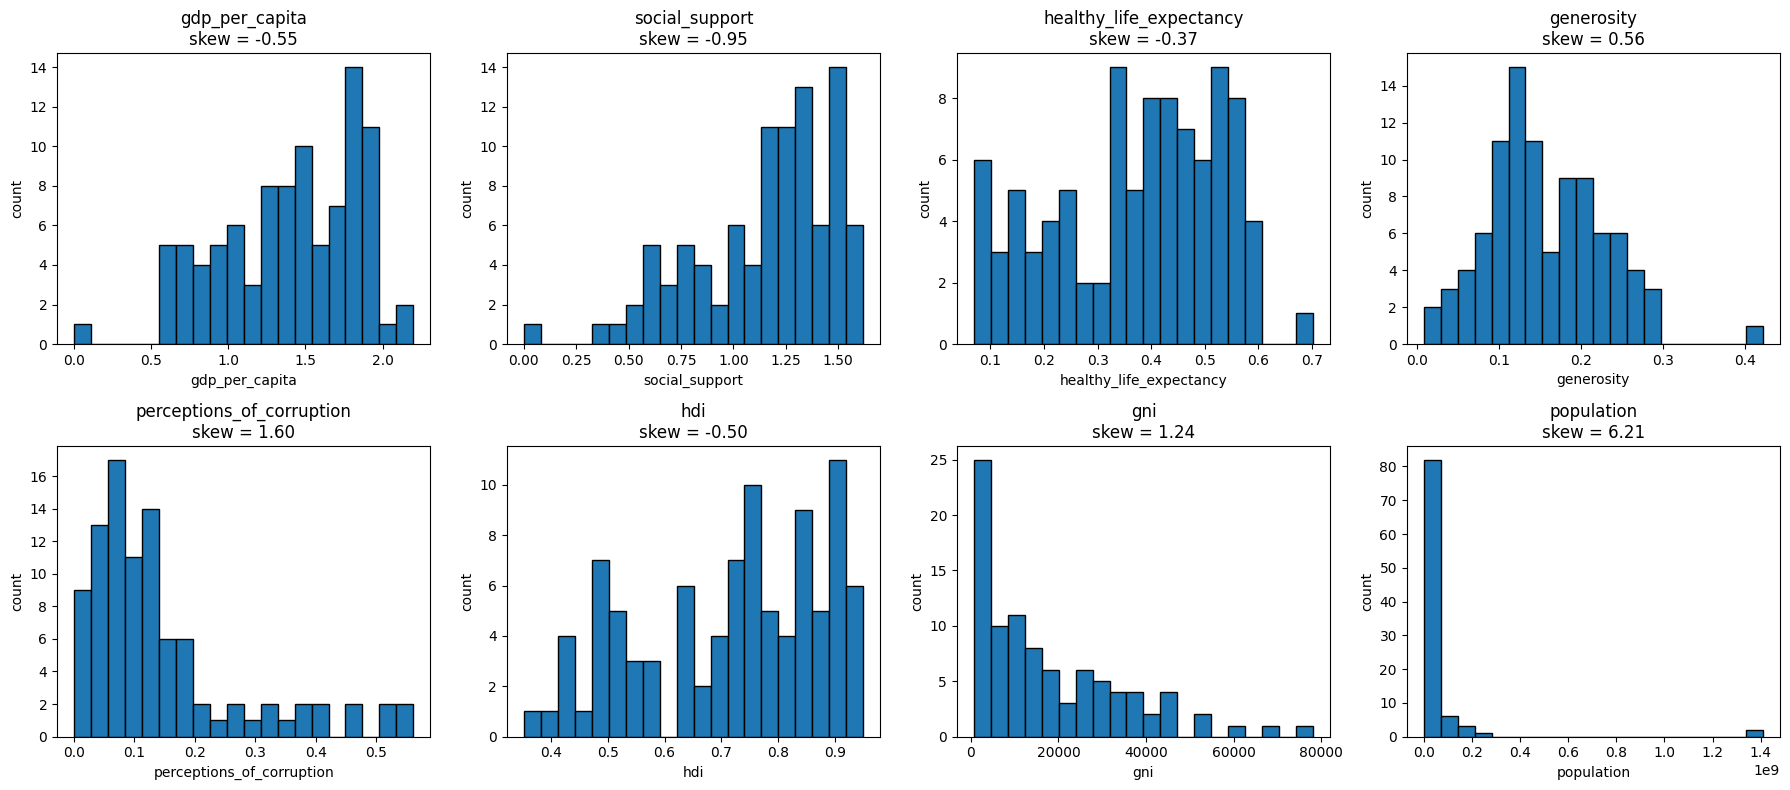

population                   6.21
perceptions_of_corruption    1.60
gni                          1.24
generosity                   0.56
healthy_life_expectancy     -0.37
hdi                         -0.50
gdp_per_capita              -0.55
social_support              -0.95
dtype: float64


In [ ]:
# Import dependencies
import matplotlib.pyplot as plt
import seaborn as sns

# Define list of numeric feature columns
features = ['gdp_per_capita', 'social_support', 'healthy_life_expectancy',
            'generosity', 'perceptions_of_corruption',
            'hdi', 'gni', 'population']

# Plot histograms of numeric feature values
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    ax.hist(X_train[col].dropna(), bins=20, edgecolor='black')
    skew = X_train[col].skew()
    ax.set_title(f"{col}\nskew = {skew:.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel('count')
plt.tight_layout()
plt.show()
print(X_train[features].skew().sort_values(ascending=False).round(2))

**A**:

Our target variable is happiness score, so the possible related variables could be 'gdp_per_capita', 'social_support', 'healthy_life_expectancy','hdi','perceptions_of_corruption'.

'gdp_per_capita' (-0.55), 'social_support' (-0.95), 'healthy_life_expectancy' (-0.37), and 'hdi' (-0.50) are negatively skewed to varying degrees. In contrast, 'perceptions_of_corruption' (1.60) is positively skewed, suggesting that its distribution may have a longer right tail.

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

<Axes: xlabel='count', ylabel='region'>

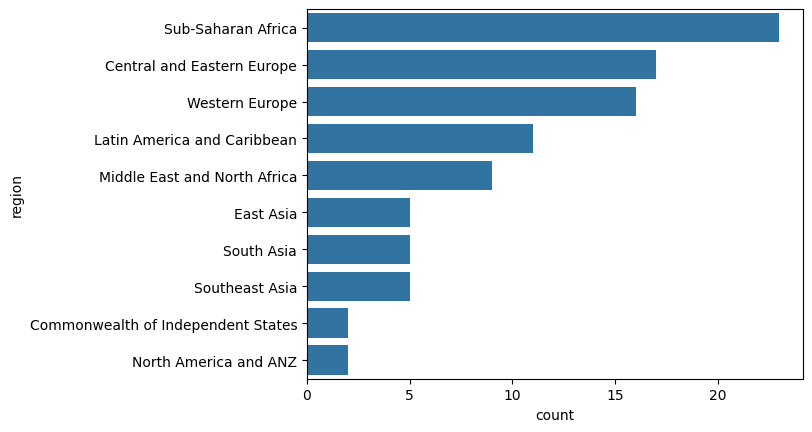

In [ ]:
# Display countplot for region feature
sns.countplot(
    data=X_train,
    y='region',
    order=X_train['region'].value_counts().index)

**A：**
The distribution of countries across regions is uneven. Sub-Saharan Africa has the largest number of countries in the training set, followed by Central and Eastern Europe and Western Europe. In contrast, the Commonwealth of Independent States and North America and ANZ have the fewest countries.

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

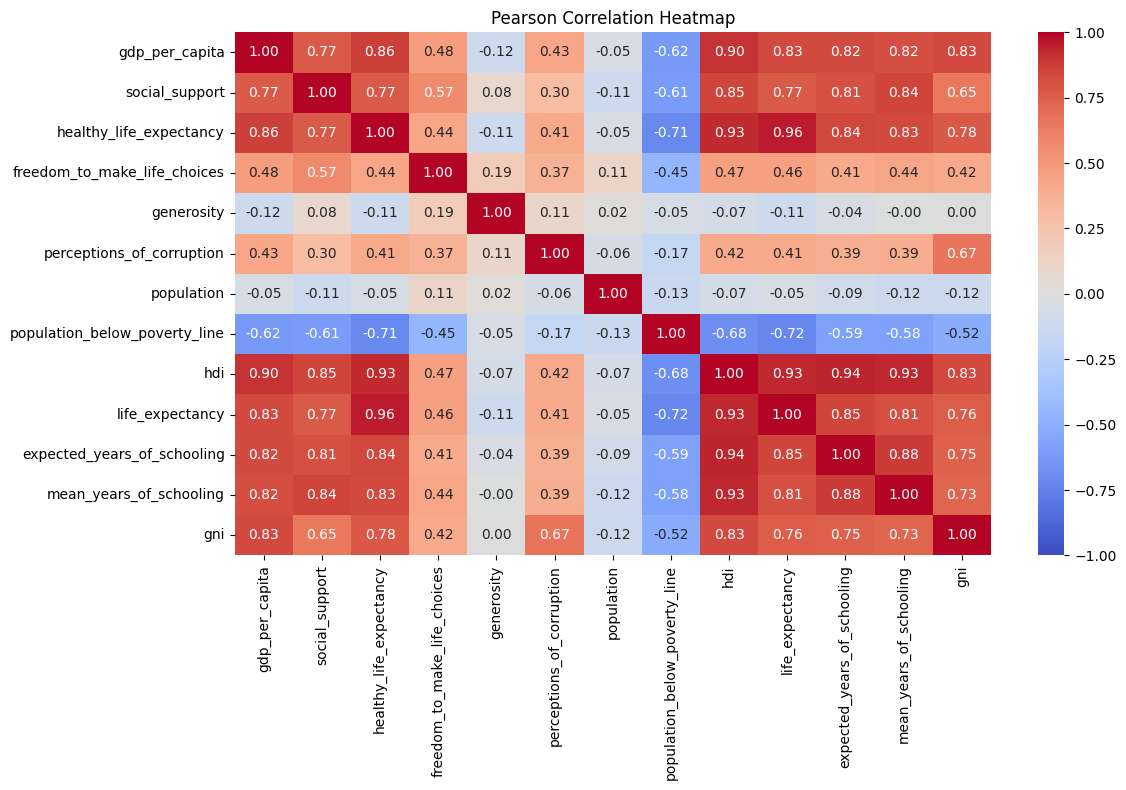

In [ ]:
# Define dataframe of only numeric features
numeric_features = X_train.select_dtypes(include='number')

#1.Pearson correlation — linear relationships
pearson_corr = numeric_features.corr(method='pearson')

# Plot pearson correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(pearson_corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            vmin=-1,
            vmax=1,
            center=0)

plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()

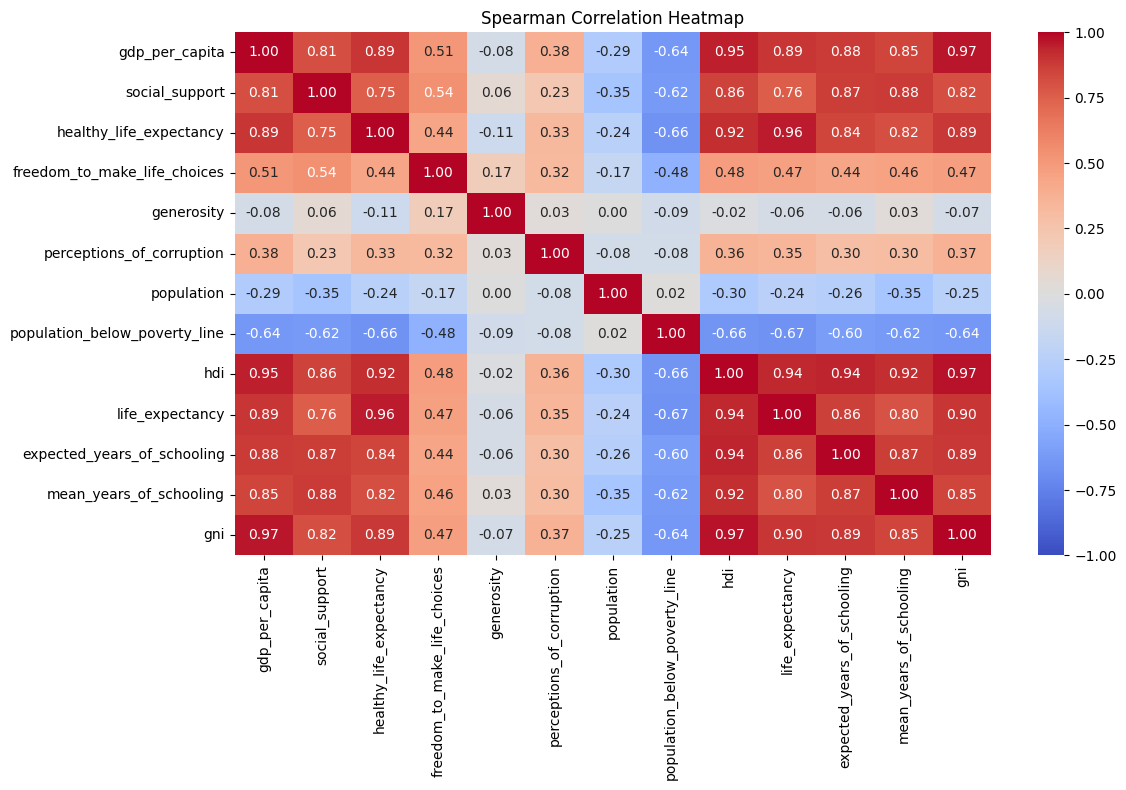

In [ ]:
#2.Spearman correlation — monotonic relationships
spearman_corr = numeric_features.corr(method='spearman')

# Plot spearman correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(spearman_corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            vmin=-1,
            vmax=1,
            center=0)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

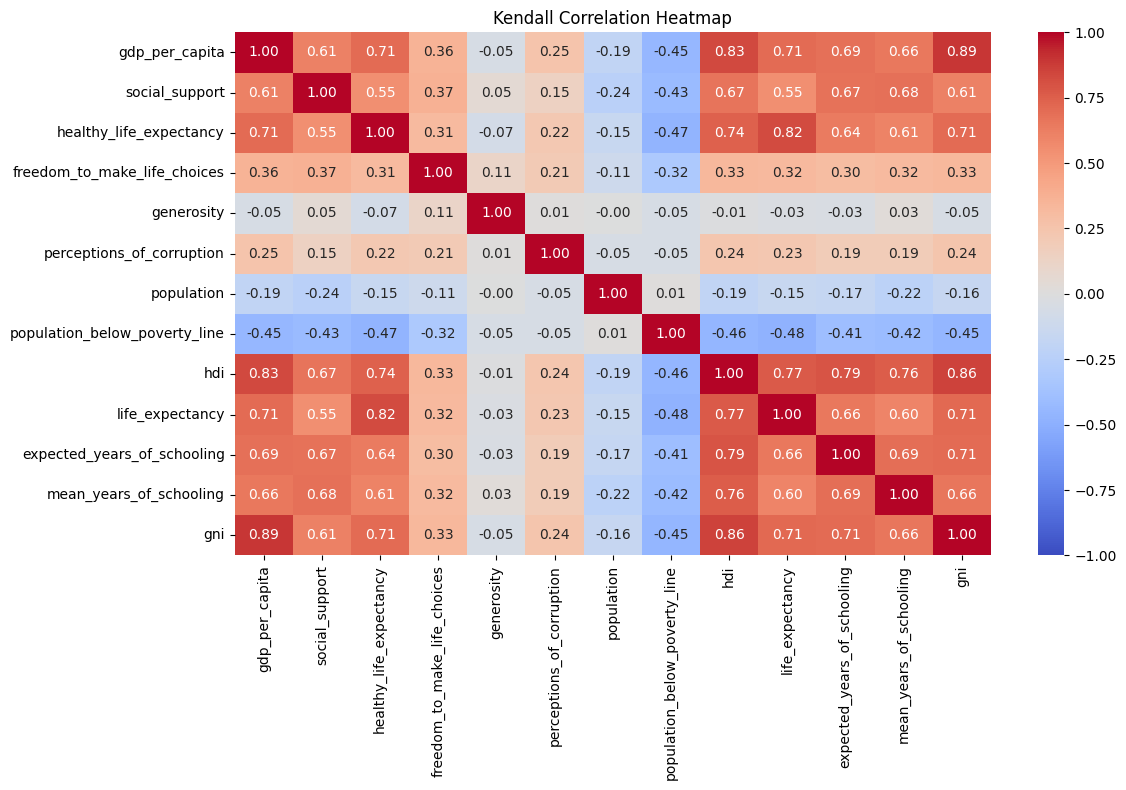

In [ ]:
#3.Kendall correlation — rank-based relationships
kendall_corr = numeric_features.corr(method='kendall')

# Plot kendall correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(kendall_corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            vmin=-1,
            vmax=1,
            center=0)

plt.title('Kendall Correlation Heatmap')
plt.tight_layout()
plt.show()

**A:**
The Pearson, Spearman, and Kendall heatmaps show similar overall patterns among the numerical features.
Strong positive correlations were observed between economic, health, and education indicators. For example, Pearson correlation between healthy_life_expectancy and life_expectancy was 0.96, while the correlation between gdp_per_capita and hdi was 0.90. Spearman correlation between gdp_per_capita and gni was 0.97, indicating a very strong positive monotonic relationship.
In contrast, population_below_poverty_line was negatively correlated with several development indicators. Its Pearson correlation with life_expectancy was -0.72, suggesting that countries with higher poverty rates tend to have lower life expectancy in this dataset.
the strong correlations among GDP per capita, GNI, HDI, and life expectancy indicators suggest potential multicollinearity.

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

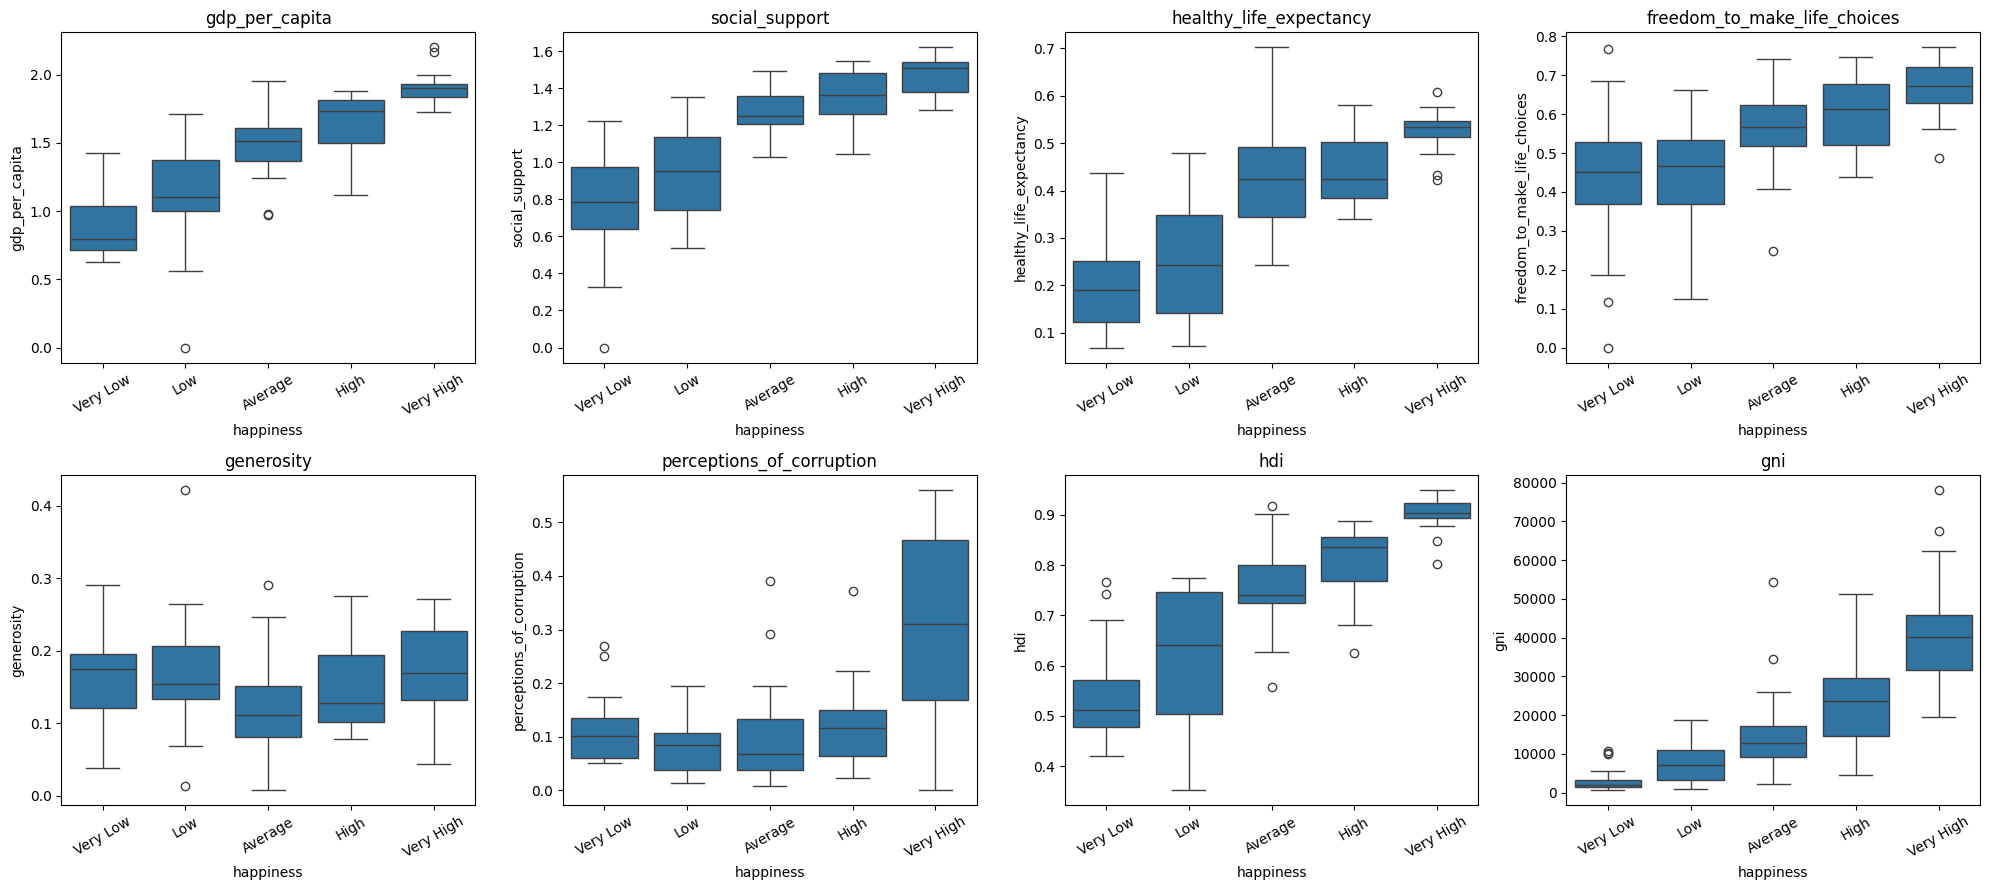

In [ ]:
order = ['Very Low', 'Low', 'Average', 'High', 'Very High']
features = ['gdp_per_capita', 'social_support', 'healthy_life_expectancy',
            'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption',
            'hdi', 'gni']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x=y_train.values, y=X_train[col], order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('happiness')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

col_0                               Very Low  Low  Average  High  Very High
row_0                                                                      
Central and Eastern Europe                 0    3        3     7          4
Commonwealth of Independent States         0    0        1     1          0
East Asia                                  0    0        4     0          1
Latin America and Caribbean                0    1        5     5          0
Middle East and North Africa               2    4        0     2          1
North America and ANZ                      0    0        0     0          2
South Asia                                 3    1        1     0          0
Southeast Asia                             1    1        2     0          1
Sub-Saharan Africa                        13    9        1     0          0
Western Europe                             0    0        2     4         10


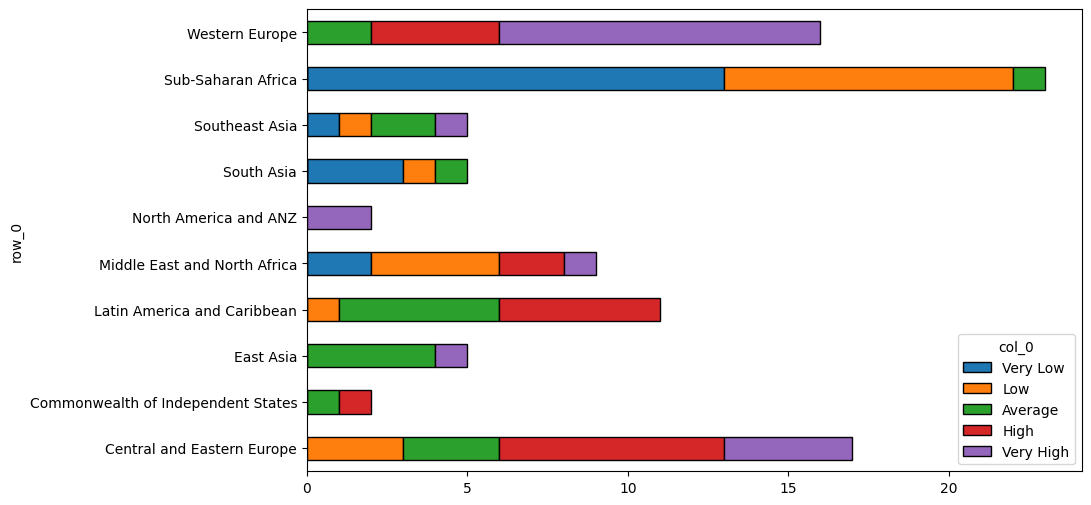

In [ ]:
ct = pd.crosstab(X_train['region'].values, y_train.values)[order]
print(ct)
ct.plot(kind='barh', stacked=True, figsize=(10, 6), edgecolor='black')
plt.show()

**A：**
GDP, life expectancy, HDI, GNI and social support rise clearly with happiness and are the strongest predictors, while generosity and corruption perception show no clear pattern. Region is also strongly linked to happiness, but the economic features are likely highly correlated, and neighboring classes overlap, so most errors will occur between adjacent happiness levels.

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

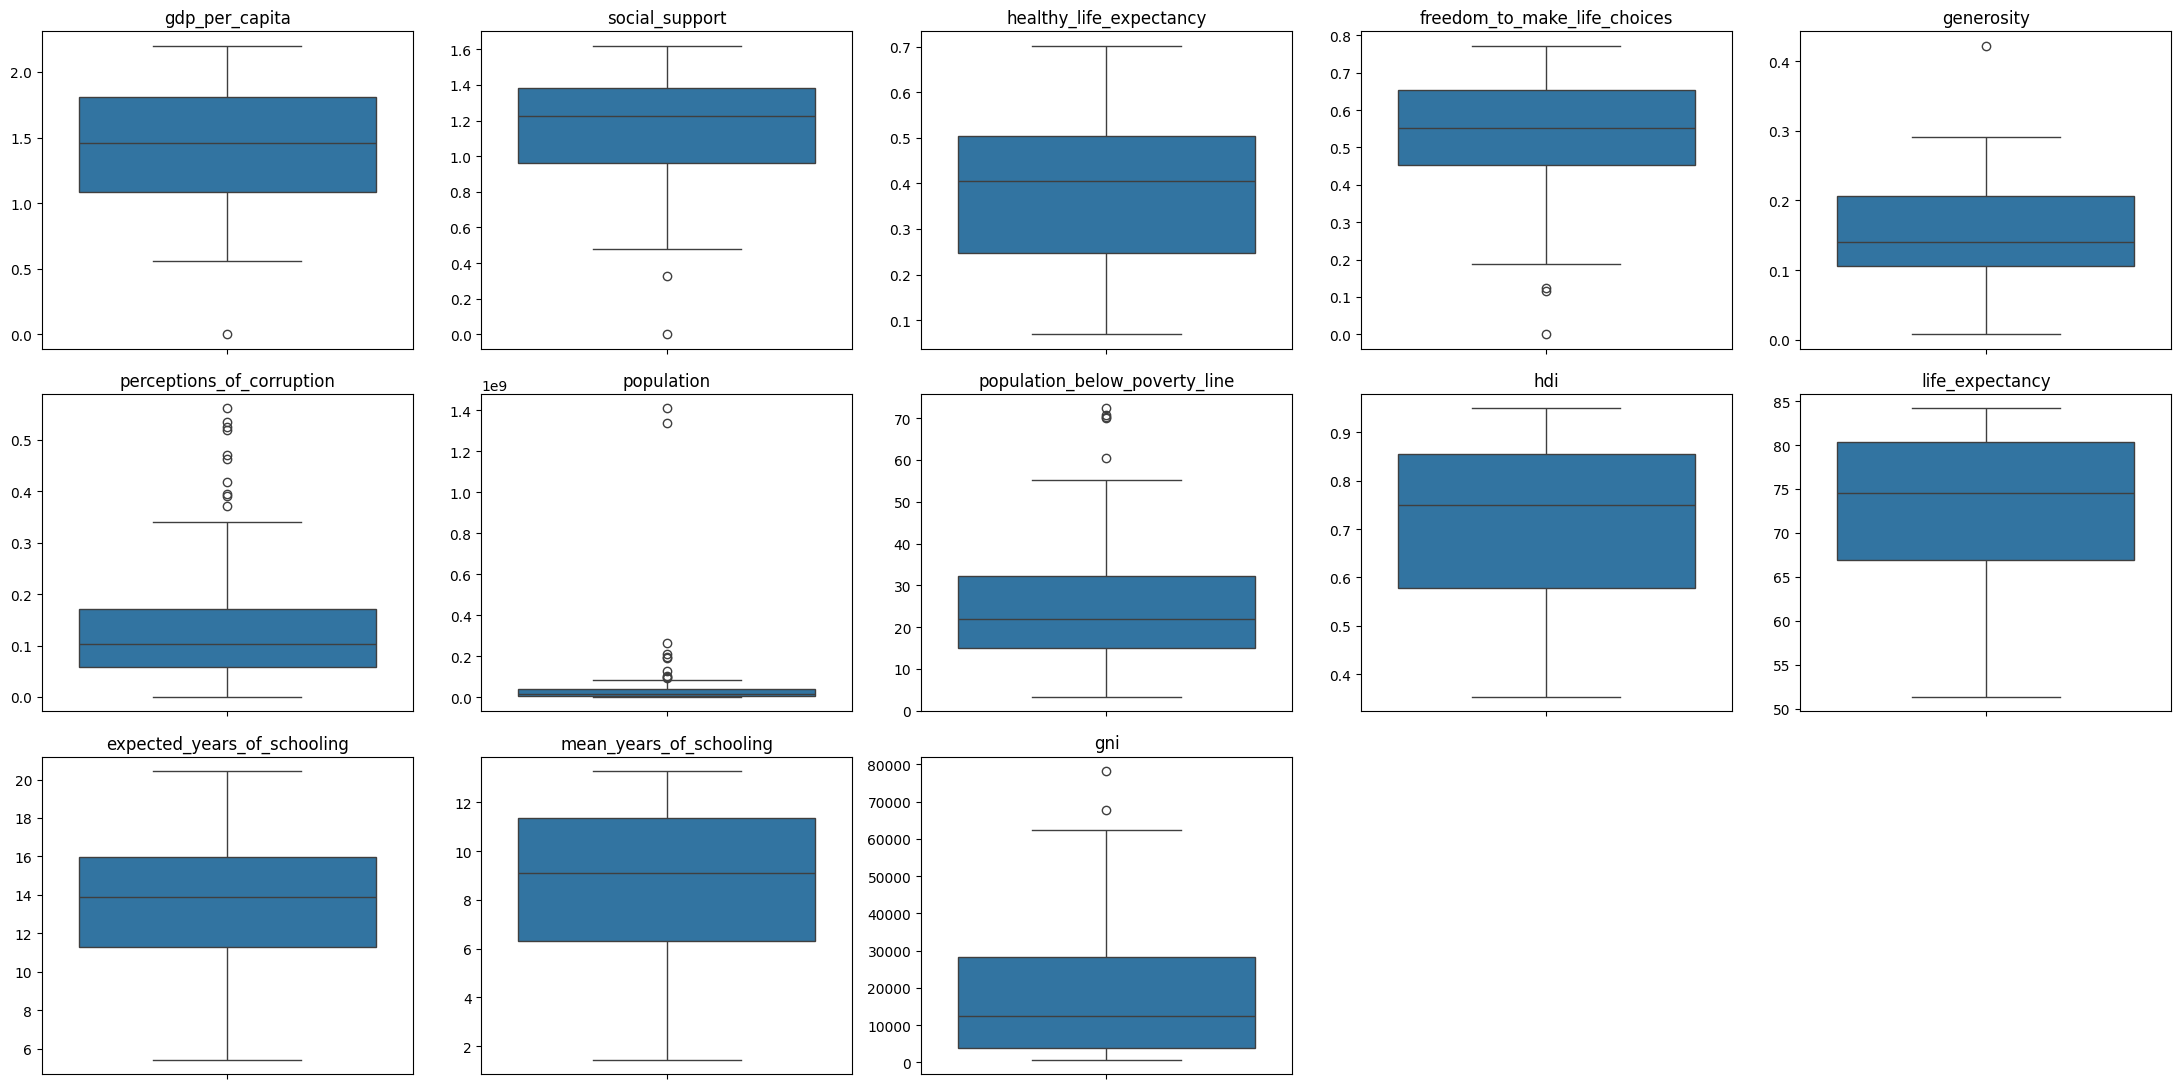

In [ ]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(3, 5, figsize=(22, 11))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**A:**
Clear outliers appear in *population, gni, perceptions_of_corruption* and *population_below_poverty_line*, while the rest are mild. They look like normal values, not errors, and the dataset is small, so they should be retained.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

**A:**
Patterns: GDP, GNI, HDI, life expectancy and social support are strongly correlated with each other and rise with happiness level, while poverty rate is negatively correlated with development indicators.

Outliers: *population, gni, perceptions_of_corruption* and *population_below_poverty_line* have clear outliers, which look genuine and should be retained.

---

## **2. Feature Engineering**

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [ ]:
# Import dependencies
import numpy as np

# Define list of numeric columns
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

# Define list of columns skew values (for comparison)
skew_before = X_train[numeric_cols].skew().sort_values(ascending=False)

# Specify columns to exclude from log transformations
excluded_cols = {"year", "rank", "happiness_rank", "happiness_score", "id"}

# Calculate skew of columns and list from highest to lowest
log_cols = [
    col for col in numeric_cols
    if col.lower() not in excluded_cols # skip columns in excluded list
    and X_train[col].notna().any()
    and X_train[col].dropna().min() >= 0
    and skew_before[col] > 1
]

# Apply log transform to columns with skew value > 1
X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

# Display skew score before log transform
print(skew_before.round(2))

population                       6.21
perceptions_of_corruption        1.60
gni                              1.24
population_below_poverty_line    1.15
generosity                       0.56
expected_years_of_schooling     -0.24
healthy_life_expectancy         -0.37
mean_years_of_schooling         -0.47
hdi                             -0.50
gdp_per_capita                  -0.55
life_expectancy                 -0.69
social_support                  -0.95
freedom_to_make_life_choices    -0.97
dtype: float64


In [ ]:
# Measure the skew values after log transform
skew_after = X_train[numeric_cols].skew()

# Display comparison of skew values before/after log transformation
comparison = pd.DataFrame({
    'before': skew_before[log_cols],
    'after':  skew_after[log_cols],
}). round(2)
print(comparison)

                               before  after
perceptions_of_corruption        1.60   1.39
population                       6.21   0.16
population_below_poverty_line    1.15  -0.37
gni                              1.24  -0.45


### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [ ]:
# Define function that calculates interaction features
def interactions(df):
    df['gdp_x_social']= df['gdp_per_capita'] * df['social_support']
    df['gdp_x_health']= df['gdp_per_capita'] * df['healthy_life_expectancy']
    df['freedom_x_social']= df['freedom_to_make_life_choices'] * df['social_support']
    df['hdi_x_social']= df['hdi'] * df['social_support']
    return df

# Apply interaction feature function to training and test set data
X_train = interactions(X_train)
X_test  = interactions(X_test)

# Display new feature columns added to train and test data
new_cols = ['gdp_x_social', 'gdp_x_health', 'freedom_x_social', 'hdi_x_social']
X_train[new_cols].describe().round(2)

,gdp_x_social,gdp_x_health,freedom_x_social,hdi_x_social
count,95.00,95.00,95.00,94.00
mean,1.74,0.59,0.65,0.88
std,0.87,0.36,0.29,0.38
min,0.00,0.00,0.00,0.00
25%,0.91,0.24,0.44,0.54
50%,1.81,0.60,0.74,0.94
75%,2.57,0.90,0.85,1.22
max,3.12,1.37,1.22,1.49


---

## **3. Data Preprocessing**

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [ ]:
# Import dependencies
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the preprocessing pipelines for both numeric and categorical data.
numeric_features = X_train.select_dtypes(include='number') # Drop all the non-numerical features from X_train
numeric_features=numeric_features.columns.tolist()         # Create list of numeric feature names

# Define numeric transformer pipeline object
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Replace NA's with median value
    ('scaler', StandardScaler())])

categorical_features = ['region']

# Define categorical transformer pipeline object
# Replacing missing values with Modal value (for categorical) and then one hot encoding.
categorical_transformer = Pipeline(steps=[
    ('imputer',  SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown= 'ignore'))])

# final preprocessor object set up with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

#Fit your preprocessor object
preprocess=preprocessor.fit(X_train)

### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

**A:**

For numeric variables, I replaced `(strategy='constant', fill_value=0)` with `(strategy='median')` so missing values are replaced by the median rather than 0. Once null values are replaced by the median, `StandardScaler()` ensures all features are on the same scale so features whos values have a large-range (for example *gni* and *population*) don’t dominate other features.
For categorical variables, missing values are filled with the most frequent category, then one-hot encoded so no order is assumed. `handle_unknown= 'ignore'` avoids errors on unseen categories.
Then I applies each pipeline to the right columns and is fitted on the training set only, which prevents data leakage. I chose to replace null values with the median imputation instead of the constant 0 because 0 is not a meaningful value for features like gdp_per_capita and would distort the distribution, while the median is robust to outliers.

In [ ]:
# Define function to transform data with preprocessor
def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

**A：**
**The preprocessor object:** the ColumnTransformer that defines which pipeline is applied to which columns.

**The preprocess object:** the same ColumnTransformer after .fit(X_train). It has learned the training medians, means, standard deviations and categories, and can now call.transform()

**The preprocessor function:** your own wrapper function that takes raw data, calls preprocess.transform(data) and returns the result. It is reusable code, and it holds no learned values itself.

**The final preprocessed_data returned:** the output of that function, a numeric array of transformed features that is passed to the model, e.g. X_train_process and X_test_process.

In [ ]:
# check shape of X training data after passing it through preprocessor function
X_train_process=preprocessor(X_train)
preprocessor(X_train).shape

(95, 27)

In [ ]:
# check shape of X testing data after passing through preprocessor function
X_test_process=preprocessor(X_test)
preprocessor(X_test).shape

(42, 27)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [ ]:
# Import dependencies
from sklearn.ensemble import RandomForestClassifier
import joblib

# Define random forest classifier model
model_1 = RandomForestClassifier(n_estimators=100, random_state=42)

#Fit model to training data
model_1.fit(X_train_process, y_train_labels)

# Save the fitted preprocessor and the trained model for reuse
joblib.dump(preprocess, 'preprocess.joblib')
joblib.dump(model_1, 'rf_model.joblib')

# Score the model accuracy on the test set
print(model_1.score(X_test_process, y_test_labels))

0.5476190476190477


---

## **5. Model Evaluation**

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

Accuracy: 0.548
Macro F1: 0.554
Weighted F1: 0.557

Classification report:
              precision    recall  f1-score   support

    Very Low       0.57      0.44      0.50         9
         Low       0.36      0.50      0.42         8
     Average       0.45      0.62      0.53         8
        High       0.67      0.50      0.57         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.55        42
   macro avg       0.58      0.55      0.55        42
weighted avg       0.59      0.55      0.56        42



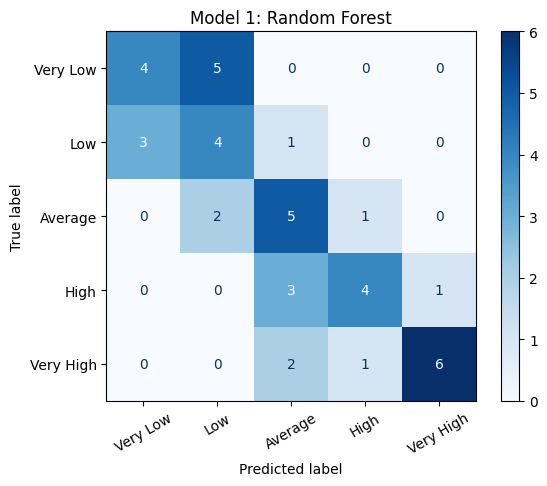

In [ ]:
# Import dependencies
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Generate predicted values (Model 1: Random Forest)
prediction_1 = model_1.predict(X_test_process)

class_names = ['Very Low', 'Low', 'Average', 'High', 'Very High']

print("Accuracy:", round(accuracy_score(y_test_labels, prediction_1), 3))
print("Macro F1:", round(f1_score(y_test_labels, prediction_1, average='macro'), 3))
print("Weighted F1:", round(f1_score(y_test_labels, prediction_1, average='weighted'), 3))

print("\nClassification report:")
print(classification_report(y_test_labels, prediction_1, target_names=class_names))

cm = confusion_matrix(y_test_labels, prediction_1)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 1: Random Forest')
plt.show()

**A：**

The Random Forest model achieved an accuracy of 0.54 on the test samples. It performs best on “Very High” , while the middle classes are weaker. The confusion matrix shows that almost all errors occur between neighboring classes (e.g., Very Low vs. Low, Average vs. High), and very few predictions are off by more than one level. Performance is clearly better than random guessing, but the small test set means these numbers are not very stable.

---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [ ]:
# Train model 2 using same preprocessor (note that you could save a new preprocessor, but we will use the same one for this example).
from sklearn.ensemble import RandomForestClassifier

# Define second random forest classifier model
model_2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42)

# Fit the model to training data
model_2.fit(X_train_process, y_train_labels)

# Print training and test accuracy
print("Train accuracy:", round(model_2.score(X_train_process, y_train_labels), 3))
print("Test accuracy:", round(model_2.score(X_test_process,  y_test_labels), 3))

Train accuracy: 0.958
Test accuracy: 0.524


### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

**A：**
I changed "n_estimators=300, max_depth=5, min_samples_leaf=2, max_features='sqrt'."
Each of these parameter controls number of trees, maximum tree depth, minimum samples per leaf, and number of features tried at each split reletively.But the Result Test accuracy stayed at 0.524 (same as Model 1) while train accuracy was 0.958, so the model still overfits. With only 42 test samples, the evaluation results may be unreliable and highly variable.

Accuracy: 0.524
Macro F1: 0.521

Classification report:
              precision    recall  f1-score   support

    Very Low       0.50      0.44      0.47         9
         Low       0.25      0.25      0.25         8
     Average       0.50      0.75      0.60         8
        High       0.57      0.50      0.53         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.52        42
   macro avg       0.54      0.52      0.52        42
weighted avg       0.54      0.52      0.53        42



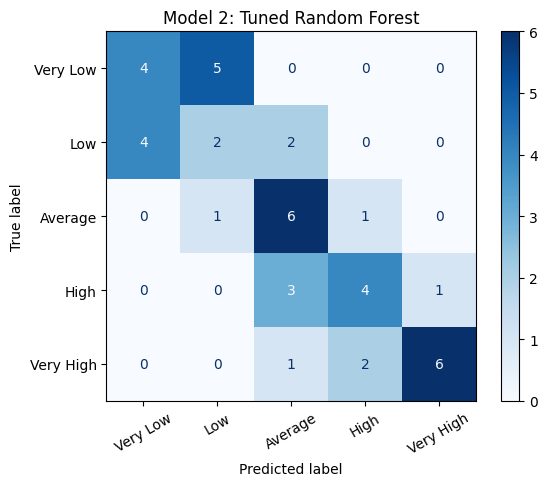

In [ ]:
#Evaluate Model 2:

#-- Generate predicted y values (Model 2)
prediction_2 = model_2.predict(X_test_process)

# Display results
print("Accuracy:", round(accuracy_score(y_test_labels, prediction_2), 3))
print("Macro F1:", round(f1_score(y_test_labels, prediction_2, average='macro'), 3))
print("\nClassification report:")
print(classification_report(y_test_labels, prediction_2, target_names=class_names))

# Display confusion matrix
cm = confusion_matrix(y_test_labels, prediction_2)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 2: Tuned Random Forest')
plt.show()

### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

**A：**

It is not worth making more changes to the parameters of the model manually. Model 2 (0.524) gives a similar accuracy as Model 1 (0.548), and with only 42 test samples a single prediction is worth about 2.4%, so tweaking values by hand and comparing test scores just fits noise and risks overfitting to the test set.

 A better alternative is automated hyperparameter search with cross-validation, such as GridSearchCV or RandomizedSearchCV. They test many parameter combinations, score each one on cross-validation folds of the training data, and return the best configuration. The test set is then used only once for the final evaluation.

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [ ]:
# Import dependencies
from sklearn.model_selection import GridSearchCV

# Train a third model using GridSearchCV

# Define param grid
param_grid = {
    'n_estimators':     np.arange(100, 401, 100).tolist(),
    'max_depth':        np.arange(3, 10, 2).tolist(),
    'min_samples_leaf': np.arange(1, 4).tolist(),
    'max_features':     ['sqrt', 'log2']}

# Define third random forest classifier model
rf = RandomForestClassifier(random_state=42)

# Apply gridsearchCV
model_3 = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1)

# Fit the model
model_3.fit(X_train_process, y_train_labels)

# Display resulting cross validation score and best parameters
print("best mean cross-validation accuracy: {:.3f}".format(model_3.best_score_))
print("training accuracy: {:.3f}".format(model_3.score(X_train_process, y_train_labels)))
print("best parameters: {}".format(model_3.best_params_))

best mean cross-validation accuracy: 0.621
training accuracy: 1.000
best parameters: {'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


Accuracy: 0.524
Macro F1: 0.521

Classification report:
              precision    recall  f1-score   support

    Very Low       0.50      0.44      0.47         9
         Low       0.25      0.25      0.25         8
     Average       0.50      0.75      0.60         8
        High       0.57      0.50      0.53         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.52        42
   macro avg       0.54      0.52      0.52        42
weighted avg       0.54      0.52      0.53        42



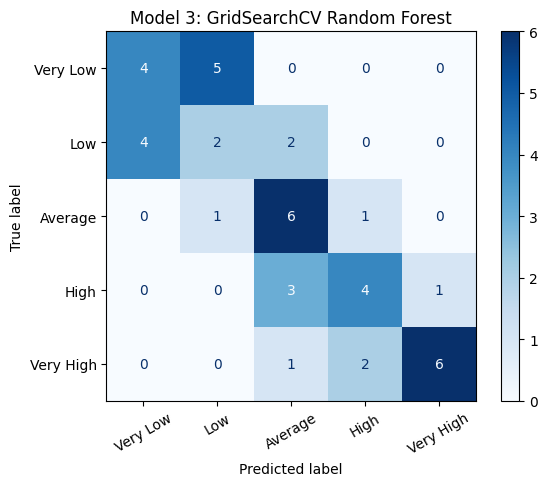

In [ ]:
#Evaluate Model 3:

#-- Generate predicted values
prediction_3 = model_3.predict(X_test_process)

# Display results
print("Accuracy:", round(accuracy_score(y_test_labels, prediction_3), 3))
print("Macro F1:", round(f1_score(y_test_labels, prediction_3, average='macro'), 3))
print("\nClassification report:")
print(classification_report(y_test_labels, prediction_3, target_names=class_names))

# Display confusion matrix
cm = confusion_matrix(y_test_labels, prediction_3)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 3: GridSearchCV Random Forest')
plt.show()

### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [ ]:
# Here are several classic ML architectures you can consider choosing from to experiment with next:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

#Baseline SVC
svc_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svc_model.fit(X_train_process, y_train_labels)

# Generate predicted values
prediction_svc = svc_model.predict(X_test_process)

# Display results
print("Test Accuracy: ", round(accuracy_score(y_test_labels, prediction_svc), 3))
print("Test Macro F1: ", round(f1_score(y_test_labels, prediction_svc, average='macro'), 3))
print(classification_report(y_test_labels, prediction_svc, target_names=class_names))

Test Accuracy:  0.548
Test Macro F1:  0.54
              precision    recall  f1-score   support

    Very Low       0.60      0.67      0.63         9
         Low       0.33      0.25      0.29         8
     Average       0.50      0.75      0.60         8
        High       0.44      0.50      0.47         8
   Very High       1.00      0.56      0.71         9

    accuracy                           0.55        42
   macro avg       0.58      0.54      0.54        42
weighted avg       0.59      0.55      0.55        42



In [ ]:
# SVC using gridsearchCV

# Define param grid
param_svc = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1],
    'kernel': ['rbf', 'linear']}

# Define the model
grid_SVC = GridSearchCV(
    SVC(random_state=42),
    param_svc,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit the model
grid_SVC.fit(X_train_process, y_train_labels)

# Display the test results
print("Best params:", grid_SVC.best_params_)
print("Best CV accuracy:", round(grid_SVC.best_score_, 3))
print("Training accuracy:", round(grid_SVC.score(X_train_process, y_train_labels), 3))
print("Training macro F1:", round(f1_score(y_train_labels, grid_SVC.predict(X_train_process), average='macro'), 3))

Best params: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.632
Training accuracy: 0.947
Training macro F1: 0.947


Test Accuracy: 0.5
Test Macro F1: 0.512

Test Classification report:
              precision    recall  f1-score   support

    Very Low       0.30      0.33      0.32         9
         Low       0.33      0.50      0.40         8
     Average       0.50      0.38      0.43         8
        High       0.71      0.62      0.67         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.50        42
   macro avg       0.54      0.50      0.51        42
weighted avg       0.54      0.50      0.51        42



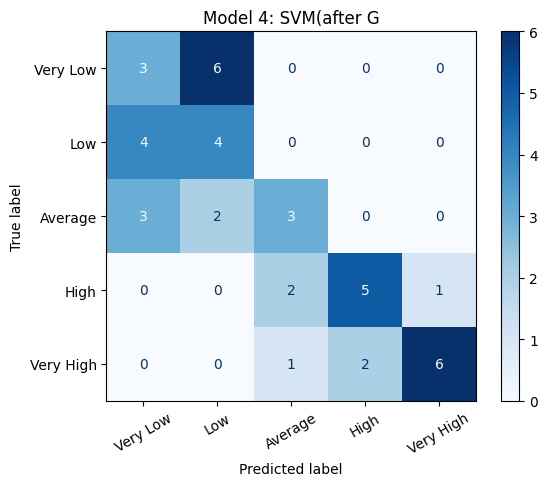

In [ ]:
# Generate predicted values
prediction_SVC_grid = grid_SVC.predict(X_test_process)

# Display results
print("Test Accuracy:", round(accuracy_score(y_test_labels, prediction_SVC_grid), 3))
print("Test Macro F1:", round(f1_score(y_test_labels, prediction_SVC_grid, average='macro'), 3))
print("\nTest Classification report:")
print(classification_report(y_test_labels, prediction_SVC_grid, target_names=class_names))

# Display confusion matrix
cm = confusion_matrix(y_test_labels, prediction_SVC_grid)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 4: SVM(after G')
plt.show()

Test Accuracy: 0.571
Test Macro F1: 0.569

Test Classification report:
              precision    recall  f1-score   support

    Very Low       0.64      0.78      0.70         9
         Low       0.43      0.38      0.40         8
     Average       0.40      0.50      0.44         8
        High       0.56      0.62      0.59         8
   Very High       1.00      0.56      0.71         9

    accuracy                           0.57        42
   macro avg       0.60      0.57      0.57        42
weighted avg       0.61      0.57      0.58        42



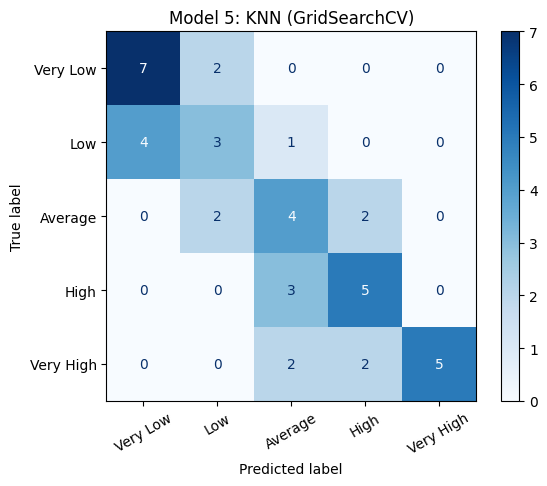

In [ ]:
# Import dependencies
from sklearn.neighbors import KNeighborsClassifier

# baseline KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_process, y_train_labels)
prediction_knn = knn_model.predict(X_test_process)

# Display results
print("Test Accuracy:", round(accuracy_score(y_test_labels, prediction_knn), 3))
print("Test Macro F1:", round(f1_score(y_test_labels, prediction_knn, average='macro'), 3))
print("\nTest Classification report:")
print(classification_report(y_test_labels, prediction_knn, target_names=class_names))

# Display confusion matrix
cm = confusion_matrix(y_test_labels, prediction_knn)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 5: KNN (GridSearchCV)')
plt.show()

In [ ]:
# KNN model using gridsearch CV

# Define param grid
param_KNN = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Define model
grid_KNN = GridSearchCV(
    KNeighborsClassifier(),
    param_KNN,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit the model
grid_KNN.fit(X_train_process, y_train_labels)

# Display best params and CV accuracy
print("Best params:", grid_KNN.best_params_)
print("Best CV accuracy:", round(grid_KNN.best_score_, 3))
print("Training accuracy:", round(grid_KNN.score(X_train_process, y_train_labels), 3))
print("Training macro F1:", round(f1_score(y_train_labels, grid_KNN.predict(X_train_process), average='macro'), 3))

Best params: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'}
Best CV accuracy: 0.6
Training accuracy: 0.684
Training macro F1: 0.68


Test Accuracy: 0.571
Test Macro F1: 0.569

Classification report:
              precision    recall  f1-score   support

    Very Low       0.64      0.78      0.70         9
         Low       0.43      0.38      0.40         8
     Average       0.40      0.50      0.44         8
        High       0.56      0.62      0.59         8
   Very High       1.00      0.56      0.71         9

    accuracy                           0.57        42
   macro avg       0.60      0.57      0.57        42
weighted avg       0.61      0.57      0.58        42



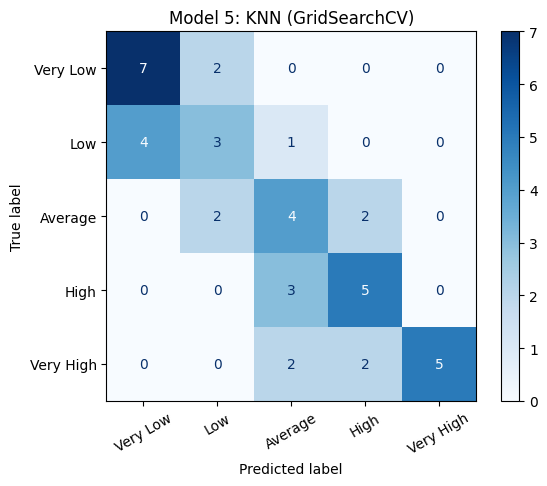

In [ ]:
# Generate predicted values (KNN GridSearchCV)
prediction_knn_grid = grid_KNN.predict(X_test_process)

# Display accuracy and macro F1
print("Test Accuracy:", round(accuracy_score(y_test_labels, prediction_knn_grid), 3))
print("Test Macro F1:", round(f1_score(y_test_labels, prediction_knn_grid, average='macro'), 3))
print("\nClassification report:")
print(classification_report(y_test_labels, prediction_knn_grid, target_names=class_names))

# Display confusion matrix
cm = confusion_matrix(y_test_labels, prediction_knn_grid)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Model 5: KNN (GridSearchCV)')
plt.show()

### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

**A:**
I tuned SVC and KNN.

For SVC, I searched C, gamma, and kernel (RBF vs. linear) with 5-fold CV on accuracy. The best setting was C=10, kernel='linear'. The linear kernel winning suggests the classes are close to linearly separable here, which makes sense because the WHR factor columns are additive contributions to the happiness score. However, the tuned SVC (test accuracy 0.50) did not beat the default RBF SVC (0.548).

For KNN, I varied n_neighbors, weights (uniform vs. distance-weighted), and metric. Baseline KNN with k=5 reached 0.571 accuracy on the test set, while the tuned KNN reached 0.571.

---

## **7. Basic Deep Learning**

In [ ]:
# Now experiment with deep learning models:

# Import dependencies
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation

# Set random seed
keras.utils.set_random_seed(42)

# Preprocess input features
X_train_processed = preprocessor(X_train)   # preprocessor function defined earlier
X_test_processed  = preprocessor(X_test)

# Count features in input data
feature_count = X_train_processed.shape[1]

# Encode categorical labels as one-hot (5 columns, one per happiness category)
y_train_oh = pd.get_dummies(y_train_labels, dtype=int)
y_test_oh  = pd.get_dummies(y_test_labels, dtype=int)

# Number of classes = number of neurons in the output layer
n_classes = y_train_oh.shape[1]

# Define a Neural Network Model (model 1) with 5 layers
keras_model = Sequential([
    Dense(128, input_shape=(feature_count,)),
    Activation('relu'),
    Dense(64),
    Activation('relu'),
    Dense(64),
    Activation('relu'),
    Dense(32),
    Activation('relu'),
    Dense(5),             # Will take the input 5 for five possible outcomes.
    Activation('softmax'),
])

# Compile model
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fit model to the training set (and save the history)
history = keras_model.fit(X_train_processed, y_train_oh, ## Note that keras models require a one-hot-encoded y_train object
               batch_size = 20,
               epochs = 300,
               validation_split=0.25,
               verbose = 0)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Display model training scores

print("Final Epoch scores")
print("-" * 30)

# Display training scores (final epoch)
print(f'Training Accuracy: {history.history["accuracy"][-1]:.4f}')
print(f'Training Loss: {history.history["loss"][-1]:.4f}')

# Display validation scores (final epoch)
print(f'Validation Accuracy: {history.history["val_accuracy"][-1]:.4f}')
print(f'Validation Loss: {history.history["val_loss"][-1]:.4f}')

Final Epoch scores
------------------------------
Training Accuracy: 0.9859
Training Loss: 0.1382
Validation Accuracy: 0.4167
Validation Loss: 2.1106


This model scored a **98.6%** training accuracy and a **41.7%** validation accuracy. This indicates that the model predicted 70 out of the 71 countries it trained on correctly. Of the 95 countries in the training set, the `validation_split=0.25` parameter kept 24 countries out of the training set to use as validation, only 10 of which the model predicted correctly. The large gap between the training accuracy score and the validation accuracy score indicates the model is overfitting and might not generalize well to unseen test data.

### **Discussion Question**

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

---------------------------------------------

All hidden layers used the relu activation function. Softmax Function was used in the final layer to transform a vector of numbers into a probability distribution, where each value represents the likelihood of a possible class. It uses 1 nueron per class and is commonly used for multiclass classification in keras models.


### **Discussion Question**


---


Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?





Training for 300 epochs is more than necessary and the model should not be trained longer. There are multiple reasons for this:

1. Adding more epochs is inefficient. More epochs will increase training time and resources without improving accuracy.
2. More epochs risk overfitting the model, leading to the model being less effective at analyzing unseen data.

The above model is overfit. There is a large gap between the accuracy score on the last epoch compared to the validation score.



---



### **Discussion Question**


---


Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?





`Categorical crossentropy` is the specific loss function used in this model. It is a commonly used loss function for models that perform multiclass catgorization and I wouldn't change it.

`sgd` (stochastic gradient descent) is an optimizer used to update the weights of the model after each epoch. I would have used `optimizer='adam'` because it is widely used as default.


---






### **Plot Training Curves**

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

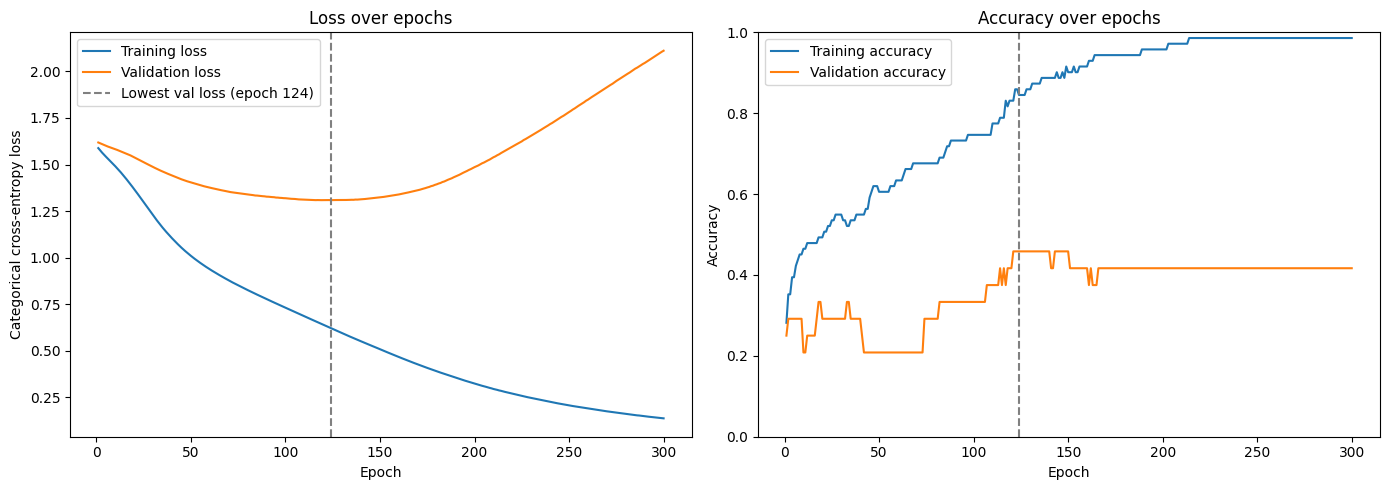

Final training accuracy: 0.986
Final validation accuracy: 0.417
Lowest validation loss: 1.309 at epoch 124


In [ ]:
# Plot training and validation curves (loss and accuracy in separate panels)

# Get the training history from the last .fit() run
hist = history.history
epochs = range(1, len(hist['loss']) + 1)

# Define epoch with the lowest validation loss score
best_epoch = np.argmin(hist['val_loss']) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, hist['loss'], label='Training loss')
axes[0].plot(epochs, hist['val_loss'], label='Validation loss')
axes[0].axvline(best_epoch, linestyle='--', color='gray',
                label=f'Lowest val loss (epoch {best_epoch})')
axes[0].set_title('Loss over epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical cross-entropy loss')
axes[0].legend()

# Accuracy curves
axes[1].plot(epochs, hist['accuracy'], label='Training accuracy')
axes[1].plot(epochs, hist['val_accuracy'], label='Validation accuracy')
axes[1].axvline(best_epoch, linestyle='--', color='gray')
axes[1].set_title('Accuracy over epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()


print(f"Final training accuracy: {hist['accuracy'][-1]:.3f}")
print(f"Final validation accuracy: {hist['val_accuracy'][-1]:.3f}")
print(f"Lowest validation loss: {min(hist['val_loss']):.3f} at epoch {best_epoch}")

### **Evaluate the Neural Network on the Test Set**

In [ ]:
#-- Generate predicted y values

#Note: Keras predict returns class probabilities (one column per class).
#Use np.argmax(..., axis=1) to get the predicted column index for each row.
prediction_column_index = np.argmax(keras_model.predict(preprocessor(X_test)), axis=1)

# extract correct prediction labels
prediction_labels = [y_train_oh.columns[i] for i in prediction_column_index]

# Show model performance by comparing prediction_labels with true labels
print("Accuracy:", accuracy_score(y_test_labels, prediction_labels))
print(confusion_matrix(y_test_labels, prediction_labels))
print(classification_report(y_test_labels, prediction_labels,
                            target_names=['Very Low', 'Low', 'Average', 'High', 'Very High']))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Accuracy: 0.5476190476190477
[[4 5 0 0 0]
 [4 3 1 0 0]
 [1 0 6 1 0]
 [0 0 4 3 1]
 [0 0 1 1 7]]
              precision    recall  f1-score   support

    Very Low       0.44      0.44      0.44         9
         Low       0.38      0.38      0.38         8
     Average       0.50      0.75      0.60         8
        High       0.60      0.38      0.46         8
   Very High       0.88      0.78      0.82         9

    accuracy                           0.55        42
   macro avg       0.56      0.54      0.54        42
weighted avg       0.56      0.55      0.55        42



In [ ]:
prediction_column_index

array([2, 2, 0, 0, 0, 4, 0, 3, 2, 4, 2, 4, 0, 2, 1, 4, 3, 0, 1, 4, 0, 2,
       4, 3, 2, 0, 0, 2, 1, 1, 1, 3, 1, 1, 2, 2, 1, 2, 2, 4, 3, 4])

The model classified 23 of the 42 countries in the testing dataset correctly, receiving an **54.7%** accuracy score, a drop from the **98.6%** accuracy score of on the training data, indicating that the model is overfit and does not generalize well to unseen data.

The category the model was most successful at predicting was "Very High", with a precision score of **88%**, indicating that when the model predicted this category, it was correct 88% of the time. The model struggled most with predicting the "Low" category, with a precision score of only **.38%**. The confusion matrix displays that the majority of errors were off by only one class, with 17 of the 18 misclassified categories being only one category off.

Overall, the model performs better than by chance, and the mistakes it made were almost always between neighboring categories. The overfitting likely occured because the model learned from 71 of the countries in the training data (validation make up the other 24), which were easy for the model to memorize, leading to overfitting the data.

### **Regularization: Dropout and Batch Normalization**

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

In [ ]:
# Import dependencies
from keras.layers import Dense, Activation, Dropout, BatchNormalization

# Define model using regularization with batch normalization and dropout

keras_model_reg = Sequential([
    Dense(128, input_shape=(feature_count,)),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(64),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(64),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(32),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.3),

    Dense(5),             # Will take the input 5 for five possible outcomes.
    Activation('softmax'),
])

# Compile model
keras_model_reg.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fit model to the training set (and save the history)
history_reg = keras_model_reg.fit(X_train_processed, y_train_oh, ## Note that keras models require a one-hot-encoded y_train object
               batch_size=20,
               epochs=300,
               validation_split=0.25,
               verbose=0)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Print regularized model training scores
print(f'Training Accuracy: {history_reg.history["accuracy"][-1]:.4f}')
print(f'Training Loss: {history_reg.history["loss"][-1]:.4f}')

Training Accuracy: 0.8028
Training Loss: 0.4748


In [ ]:
# Evaluate the regularized model on the test set
test_score_reg = keras_model_reg.evaluate(X_test_processed, y_test_oh, batch_size=20)

# Define for table in summary section
accuracy_nn_reg = test_score_reg[1]

# Print regularized model test scores
print(f'Test Accuracy: {test_score_reg[1]:.4f}')
print(f'Test Loss: {test_score_reg[0]:.4f}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5476 - loss: 1.1685
Test Accuracy: 0.5476
Test Loss: 1.1685


Adding batch normalization and dropout resulted in lower training accuracy, from a **98.6%** training accuracy rate in the original neural network to an **80.2%** training accuracy in the regularized model. This is to be expected, with the purpose of dropout to make memorization of a dataset more difficult and to encourage a the model to learn more general patterns. The purpose of batch normalization is it rescales a layer’s outputs so they always come out centered at 0 and small. Because the dataset is small and already scaled during preprocessing, this didn't have much of an effect on the score.

the regularized model’s test accuracy was **54.7%**, the same as the original network (23 of 42 test countries), so the regularization reduced overfitting without improving performance on unseen data. This is likely because of the small size of the dataset. With only 71 countries to learn from and 42 to test on, there’s limited information for the model to learn more general patterns from, and a difference of one or two countries is within the range of random noise.

### **Activation Function Experimentation**

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [ ]:
# Define model with tahn activation function
keras_model_act = Sequential([
    Dense(128, input_shape=(feature_count,)),
    Activation('tanh'),
    Dense(64),
    Activation('tanh'),
    Dense(64),
    Activation('tanh'),
    Dense(32),
    Activation('tanh'),
    Dense(5),             # Will take the input 5 for five possible outcomes.
    Activation('softmax'),
])

# Compile model
keras_model_act.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fit model to the training set (and save the history)
history_act = keras_model_act.fit(X_train_processed, y_train_oh, ## Note that keras models require a one-hot-encoded y_train object
               batch_size = 20,
               epochs = 300,
               validation_split=0.25,
               verbose = 0)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Display model training scores
print(f'Training Accuracy: {history_act.history["accuracy"][-1]:.4f}')
print(f'Training Loss: {history_act.history["loss"][-1]:.4f}')

Training Accuracy: 0.9718
Training Loss: 0.2314


In [ ]:
# Evaluate the model (tahn activation) on the test set
history_act_test = keras_model_act.evaluate(X_test_processed, y_test_oh, batch_size=20, verbose = 0)

# Define for table in summary section
accuracy_nn_act = history_act_test[1]

# Print model test scores
print(f'Test Accuracy: {history_act_test[1]:.4f}')
print(f'Test Loss: {history_act_test[0]:.4f}')

Test Accuracy: 0.5476
Test Loss: 1.1555


In [ ]:
# Define model with sigmoid activation function
keras_model_sig = Sequential([
    Dense(128, input_shape=(feature_count,)),
    Activation('sigmoid'),
    Dense(64),
    Activation('sigmoid'),
    Dense(64),
    Activation('sigmoid'),
    Dense(32),
    Activation('sigmoid'),
    Dense(5),             # Output layer: 5 neurons, one per happiness category
    Activation('softmax'),
])

# Compile model
keras_model_sig.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fit model to the training set (and save the history)
history_sig = keras_model_sig.fit(X_train_processed, y_train_oh,
                                  batch_size=20,
                                  epochs=300,
                                  validation_split=0.25,
                                  verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Display sigmoid model training scores
print(f'Training Accuracy: {history_sig.history["accuracy"][-1]:.4f}')
print(f'Training Loss: {history_sig.history["loss"][-1]:.4f}')

Training Accuracy: 0.2254
Training Loss: 1.5982


In [ ]:
# Evaluate the model (sigmoid activation) on the test set
test_score_sig = keras_model_sig.evaluate(X_test_processed, y_test_oh, batch_size=20, verbose=0)

# Define for table in summary section
accuracy_nn_sig = test_score_sig[1]

# Print model test scores
print(f'Test Accuracy: {test_score_sig[1]:.4f}')
print(f'Test Loss: {test_score_sig[0]:.4f}')

Test Accuracy: 0.2143
Test Loss: 1.6099


In [ ]:
# Import dependencies
from keras.layers import LeakyReLU

# Define model with LeakyReLU activation function
keras_model_leaky = Sequential([
    Dense(128, input_shape=(feature_count,)),
    LeakyReLU(),
    Dense(64),
    LeakyReLU(),
    Dense(64),
    LeakyReLU(),
    Dense(32),
    LeakyReLU(),
    Dense(5),             # Output layer: 5 neurons, one per happiness category
    Activation('softmax'),
])

# Compile model
keras_model_leaky.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fit model to the training set (and save the history)
history_leaky = keras_model_leaky.fit(X_train_processed, y_train_oh,
                                      batch_size=20,
                                      epochs=300,
                                      validation_split=0.25,
                                      verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Display LeakyReLU model training scores
print(f'Training Accuracy: {history_leaky.history["accuracy"][-1]:.4f}')
print(f'Training Loss: {history_leaky.history["loss"][-1]:.4f}')

Training Accuracy: 0.9718
Training Loss: 0.2164


In [ ]:
# Evaluate the model (LeakyReLU activation) on the test set
test_score_leaky = keras_model_leaky.evaluate(X_test_processed, y_test_oh, batch_size=20, verbose=0)

# Define for table in summary section
accuracy_nn_leaky = test_score_leaky[1]

# Print model test scores
print(f'Test Accuracy: {test_score_leaky[1]:.4f}')
print(f'Test Loss: {test_score_leaky[0]:.4f}')

Test Accuracy: 0.5714
Test Loss: 1.0610


ReLU, tanh and LeakyReLU all produced similar results (23–24 of 42 test countries predicted correctly), so the activation choice made little difference for this small network. LeakyReLU scored the highest, with a 57.14% accuracy, which is likely due to chance.  

Sigmoid failed to learn any of the data, with a 21% accuracy rate being the same as guessing, this shows the network never learned meaningful patterns of the data.

---

## **8. Explainability – SHAP Feature Importance**

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

/tmp/ipykernel_215716/3967312012.py:43: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


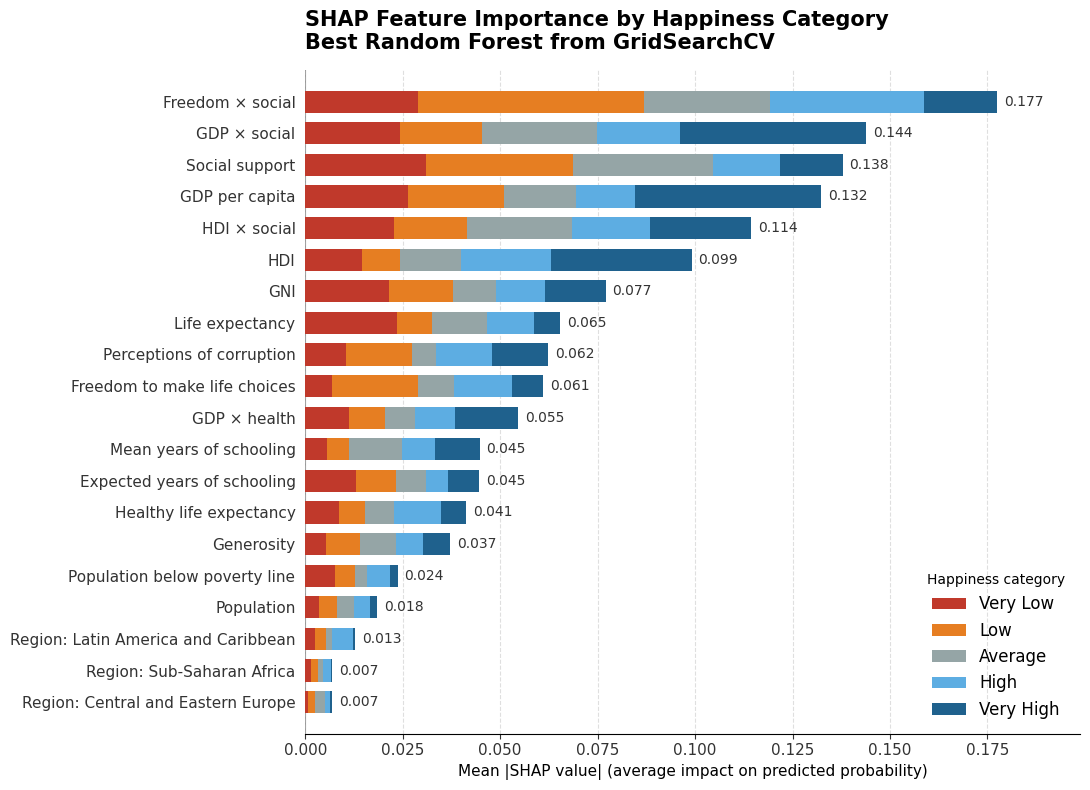

In [ ]:
# Import dependencies
import shap
from matplotlib.colors import ListedColormap

# Transform the test data using the fitted preprocessor
# (SHAP needs the same numeric feature matrix the model was trained on, not raw X_test)
X_test_processed = preprocessor(X_test)   # preprocessor function defined earlier

# Get feature names matching the columns after preprocessing
feature_names = preprocess.get_feature_names_out()
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names)

# Initialize SHAP explainer
# Explicitly use the best Random Forest from GridSearchCV (model3), since `model` was reassigned
best_rf = model_3.best_estimator_
explainer = shap.Explainer(best_rf)

# Compute SHAP values for the preprocessed test data
# This step generates Shapley values, which explain how each feature contributes to predictions
shap_values = explainer(X_test_processed)

# Generate SHAP summary plot
# This plot will show which features have the most impact on predictions
class_names = ['Very Low', 'Low', 'Average', 'High', 'Very High']

# Readable feature names: "num__gdp_x_social" -> "GDP × social"
acronyms = {'gdp': 'GDP', 'hdi': 'HDI', 'gni': 'GNI'}

def clean_name(name):
    name = name.split('__', 1)[1]                     # drop "num__" / "cat__"
    name = name.replace('region_', 'Region: ')
    name = name.replace('_x_', ' × ').replace('_', ' ')
    words = [acronyms.get(w.lower(), w) for w in name.split(' ')]
    name = ' '.join(words)
    return name[0].upper() + name[1:]

clean_names = [clean_name(n) for n in feature_names]

# Ordered colors: red (least happy) -> blue (most happy)
category_colors = ListedColormap(['#c0392b', '#e67e22', '#95a5a6', '#5dade2', '#1f618d'])

# Draw the summary plot, then style it before showing
shap.summary_plot(
    [shap_values.values[:, :, i] for i in range(len(class_names))],
    X_test_processed,
    feature_names=clean_names,
    class_names=class_names,
    class_inds='original',
    color=category_colors,
    plot_type='bar',
    plot_size=(11, 8),
    show=False
)

ax = plt.gca()
ax.set_title('SHAP Feature Importance by Happiness Category\nBest Random Forest from GridSearchCV',
             fontsize=15, fontweight='bold', loc='left', pad=15)
ax.set_xlabel('Mean |SHAP value| (average impact on predicted probability)', fontsize=11)
ax.tick_params(axis='y', labelsize=11)

# Clean up the frame and add light gridlines
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Legend title and border
legend = ax.get_legend()
legend.set_title('Happiness category')
legend.get_frame().set_edgecolor('lightgray')

# Show each feature's total importance at the end of its bar
bar_ends = {}
for bar in ax.patches:
    y_mid = round(bar.get_y() + bar.get_height() / 2, 3)
    bar_ends[y_mid] = max(bar_ends.get(y_mid, 0), bar.get_x() + bar.get_width())

max_end = max(bar_ends.values())
for y_mid, total in bar_ends.items():
    ax.text(total + max_end * 0.01, y_mid, f'{total:.3f}',
            va='center', ha='left', fontsize=10, color='#333333')

ax.set_xlim(0, max_end * 1.12)   # extra room on the right so the labels fit

plt.tight_layout()
plt.show()

**SHAP feature importance for top random forest classifier model:**

The SHAP summary plot above shows the feature importance of our best-performing random forest model. Each bar represents a feature's total importance: its average impact on the model's predicted probabilities, summed across all five happiness categories. The colored segments show how that impact is divided among the categories.

The most influential feature is freedom × social (`num__freedom_x_social`), an interaction feature created in Part 2. It's SHAP value of **0.177** means that, on average, it affects the model's predicted probabilities by about 0.177 per country across all five categories. Its impact is not evenly distributed: the orange "Low" segment is the largest, indicating that freedom × social has its strongest effect on the model's predicted probability of a country being classified as "Low" happiness.



## **Explaining the Deep Learning Model**

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

____________________________





In [ ]:
# Transform the training and test data using the fitted preprocessor
# (SHAP needs the same numeric feature matrix the model was trained on, not raw data)
X_train_nn = preprocessor(X_train)
X_test_nn  = preprocessor(X_test)

# Get feature names matching the columns after preprocessing
feature_names = preprocess.get_feature_names_out()

# Initialize SHAP explainer
background = shap.sample(X_train_nn, 50, random_state=42)
explainer_nn = shap.KernelExplainer(lambda x: keras_model.predict(x, verbose=0), background)

# Compute SHAP values for a subset of the preprocessed test data
X_explain = X_test_nn[:20]
shap_values_nn = explainer_nn.shap_values(X_explain)

# Convert to one array per class if needed (format expected by summary_plot)
if not isinstance(shap_values_nn, list):
    shap_values_nn = [shap_values_nn[:, :, i] for i in range(shap_values_nn.shape[2])]


  0%|          | 0/20 [00:00<?, ?it/s]

/tmp/ipykernel_215716/2011754531.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


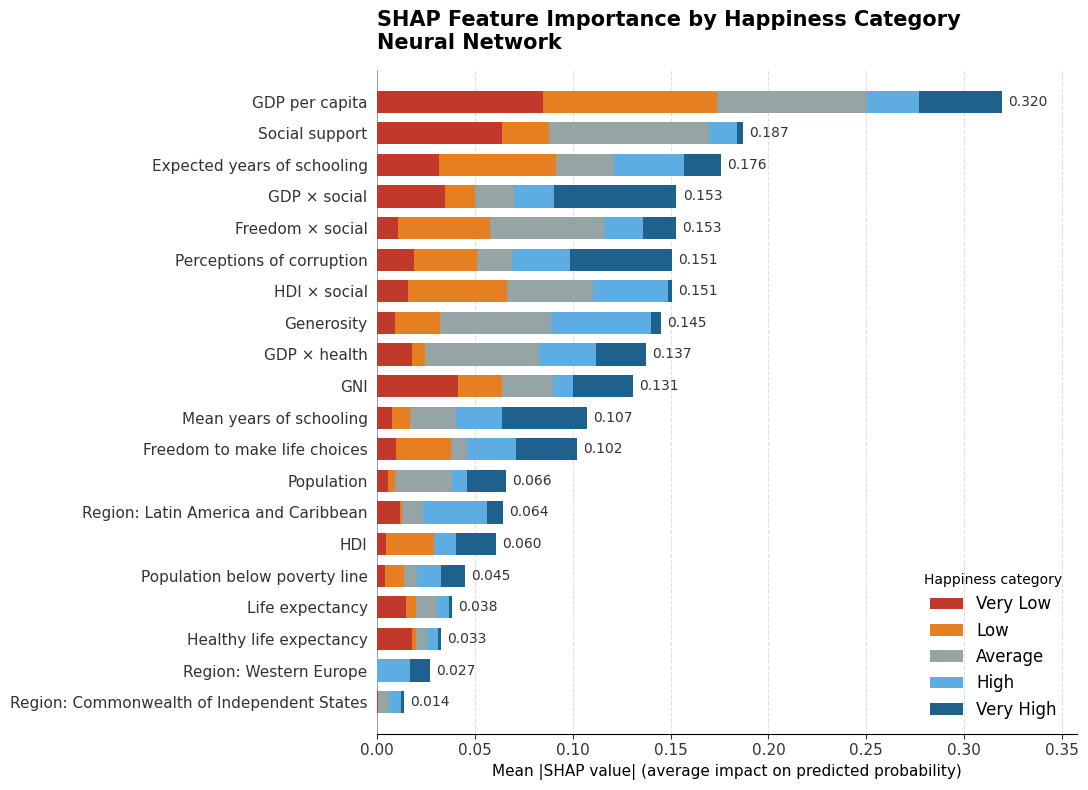

In [ ]:
# Generate SHAP summary plot
class_names = ['Very Low', 'Low', 'Average', 'High', 'Very High']

# Readable feature names: "num__gdp_x_social" -> "GDP × social"
acronyms = {'gdp': 'GDP', 'hdi': 'HDI', 'gni': 'GNI'}

# Define name formatting function
def clean_name(name):
    name = name.split('__', 1)[1]
    name = name.replace('region_', 'Region: ')
    name = name.replace('_x_', ' × ').replace('_', ' ')
    words = [acronyms.get(w.lower(), w) for w in name.split(' ')]
    name = ' '.join(words)
    return name[0].upper() + name[1:]

clean_names = [clean_name(n) for n in feature_names]

# Ordered colors: red (least happy) -> blue (most happy)
category_colors = ListedColormap(['#c0392b', '#e67e22', '#95a5a6', '#5dade2', '#1f618d'])

# Define summary plot
shap.summary_plot(
    shap_values_nn,
    X_explain,
    feature_names=clean_names,
    class_names=class_names,
    class_inds='original',
    color=category_colors,
    plot_type='bar',
    plot_size=(11, 8),
    show=False
)

ax = plt.gca()
ax.set_title('SHAP Feature Importance by Happiness Category\nNeural Network',
             fontsize=15, fontweight='bold', loc='left', pad=15)
ax.set_xlabel('Mean |SHAP value| (average impact on predicted probability)', fontsize=11)
ax.tick_params(axis='y', labelsize=11)

# Clean up the frame and add light gridlines
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Legend title and border
legend = ax.get_legend()
legend.set_title('Happiness category')
legend.get_frame().set_edgecolor('lightgray')

# Show each feature's total importance at the end of its bar
bar_ends = {}
for bar in ax.patches:
    y_mid = round(bar.get_y() + bar.get_height() / 2, 3)
    bar_ends[y_mid] = max(bar_ends.get(y_mid, 0), bar.get_x() + bar.get_width())

max_end = max(bar_ends.values())
for y_mid, total in bar_ends.items():
    ax.text(total + max_end * 0.01, y_mid, f'{total:.3f}',
            va='center', ha='left', fontsize=10, color='#333333')

ax.set_xlim(0, max_end * 1.12)
plt.tight_layout()
plt.show()

**SHAP feature importance for nueral network model**


This SHAP summary plot provides a clear reasoning of how our baseline nueral network model makes decisions using feature importance. This model's most important feature was **GDP per capita**, with a SHAP score of **approximately 0.320**. This indicates this feature affects the model's predicted probabilities by about 0.320 per country on average, across all five categories. While our SHAP summary bar plot tells us the most important feature, it does not tell us in which direction the probability of the predicted class is affected (more or less probable), only magnitude.

These SHAP values make it easier to justify this specific model's predictions by ranking and providing scores displaying feature importance. It is important to note, that while SHAP values can help explain why a model makes specific predictions, that does not necessarily describe the relationship between GDP per capita and a country's happiness score (and associated categories) in the real world.


### **Experimentation**

In [ ]:
# Import dependencies
from sklearn.linear_model import LogisticRegression

# Define logistic regression model
logreg = LogisticRegression(C=.01, penalty='l2', max_iter=1000).fit(X_train_processed, y_train_labels)

# Display training and test scores
print("Training set score: {:.3f}".format(logreg.score(X_train_processed, y_train_labels)))
print("Test set score: {:.3f}".format(logreg.score(X_test_processed, y_test_labels)))

predicted_vals = logreg.predict(X_test_processed) # y_pred includes your predictions
print("logreg.predict: {}".format(predicted_vals))

logreg .coef_: [[-0.08602581 -0.09215751 -0.07149588 -0.05183853  0.0082551   0.00462428
   0.02517999  0.04405308 -0.07432069 -0.07452975 -0.04569698 -0.04988404
  -0.09452641 -0.08427115 -0.06973363 -0.0709356  -0.08448896 -0.01665126
  -0.00412176 -0.00527346 -0.01894365  0.00412729 -0.00076132  0.01313743
   0.00207518  0.03476719 -0.00828119]
 [-0.03559883 -0.05183325 -0.05025455 -0.06190242  0.03310695 -0.04888972
   0.03600678  0.01498966 -0.04354769 -0.04841544 -0.06897119 -0.05804062
  -0.00977892 -0.05770382 -0.05265676 -0.08207543 -0.0543743   0.00629373
  -0.00398871 -0.00730046 -0.01197915  0.02070323 -0.00111851 -0.00491237
   0.00035262  0.0145283  -0.0125791 ]
 [ 0.00141333  0.03448274  0.0346566   0.00417642 -0.05586041 -0.04693086
  -0.00218508 -0.04189497  0.00729337  0.03019578  0.01225312 -0.00233175
  -0.00659273  0.0046807   0.01137573  0.01314391  0.01291964 -0.01107007
   0.00559105  0.02729422  0.02234513 -0.0200424  -0.00330977  0.00155285
   0.00909101 -0.01

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

In [ ]:
# Summary table comparing test performances.


from sklearn.metrics import accuracy_score
# Define dictionary of models and associated accuracy scores
test_accuracy = {
    'Random Forest (baseline)': accuracy_score(y_test_labels, prediction_1),
    'Random Forest (tuned manually)': accuracy_score(y_test_labels, prediction_2),
    'Random Forest (GridSearchCV)': accuracy_score(y_test_labels, prediction_3),
    'SVC (baseline)': accuracy_score(y_test_labels, prediction_svc),
    'SVC (GridSearchCV)': accuracy_score(y_test_labels, prediction_SVC_grid),
    'KNN (baseline)': accuracy_score(y_test_labels, prediction_knn),
    'KNN (GridSearchCV)': accuracy_score(y_test_labels, prediction_knn_grid),
    'Logistic Regression': accuracy_score(y_test_labels, predicted_vals),
    'Neural Network (baseline)': accuracy_score(y_test_labels, prediction_labels),
    'Neural Network (BatchNorm + Dropout)': accuracy_nn_reg,
    'Neural Network (Tanh)': accuracy_nn_act,
    'Neural Network (Sigmoid)': accuracy_nn_sig,
    'Neural Network (LeakyReLU)': accuracy_nn_leaky,
}

# Define summary table dataframe
summary_table = (pd.DataFrame({'Model': list(test_accuracy.keys()),
                               'Test Accuracy': list(test_accuracy.values())})
                   .sort_values('Test Accuracy', ascending=False)
                   .reset_index(drop=True)
                   .round(3))

# Display summary table
summary_table

,Model,Test Accuracy
0,Neural Network (LeakyReLU),0.571
1,KNN (baseline),0.571
2,KNN (GridSearchCV),0.571
3,SVC (baseline),0.548
4,Random Forest (baseline),0.548
5,Neural Network (baseline),0.548
6,Logistic Regression,0.548
7,Neural Network (Tanh),0.548
8,Neural Network (BatchNorm + Dropout),0.548
9,Random Forest (tuned manually),0.524



### Final Model Comparison

| Rank | Model | Test Accuracy |
|---|---|---|
| 1 | Neural Network (LeakyReLU) | 0.571 |
| 2 | KNN (baseline) | 0.571 |
| 3 | KNN (GridSearchCV) | 0.571 |
| 4 | SVC (baseline) | 0.548 |
| 5 | Random Forest (baseline) | 0.548 |
| 6 | Neural Network (baseline) | 0.548 |
| 7 | Logistic Regression | 0.548 |
| 8 | Neural Network (Tanh) | 0.548 |
| 9 | Neural Network (BatchNorm + Dropout) | 0.548 |
| 10 | Random Forest (tuned manually) | 0.524 |
| 11 | Random Forest (GridSearchCV) | 0.524 |
| 12 | SVC (GridSearchCV) | 0.500 |
| 13 | Neural Network (Sigmoid) | 0.214 |



<br>
<br>

### **Top-Performing Models (Test Accuracy: 0.571)**

**1. Neural Network (LeakyReLU)**
- Layers: 128 → 64 → 64 → 32 → 5 (softmax)
- Activation: LeakyReLU
- Optimizer: SGD
- Loss: categorical crossentropy
- Batch size: 20
- Epochs: 300
- Validation split: 0.25

**2. KNN (GridSearchCV)**
- n_neighbors: 5
- weights: uniform
- metric: euclidean

**3. KNN (baseline)**
- n_neighbors: 5

The LeakyReLU neural network and both KNN models tied for the highest test accuracy at 57.1%, correctly classifying 24 of the 42 test countries. This was only one country more than several other models, which each correctly classified 23. With such a small test set, a single country changes accuracy by about 2.4%, so these top results are *most likely due to chance rather than a meaningful difference*.

The underlying issue is the small dataset: all non neural network models were trained on 95 countries, and the neural networks learned from only 71 after 24 were set aside for validation. With so little data, the more complex models, such as the random forest and neural networks, overfit by memorizing the training countries instead of learning general patterns. The sigmoid network was the exception, it underfit, failing to learn even the training data. KNN may have benefited slightly from being a simpler model with less capacity to memorize, which tends to help on small datasets, but overall the similar results across model types suggest that performance was limited mainly by the data rather than by the choice of model.

<br>

### **EDA**
The exploratory data analysis revealed several important patterns in the relationship between happiness levels and socioeconomic indicators. GDP per capita, social support, healthy life expectancy, and the Human Development Index (HDI) generally increased with happiness levels, suggesting that economic prosperity, social support, health, and overall human development are important predictors of happiness. The correlation heatmaps also showed strong positive relationships among GDP per capita, HDI, life expectancy, and years of schooling, indicating potential multicollinearity among these features. In contrast, generosity showed relatively weak correlations with most other variables. The regional distribution plot showed that the number of observations varied across regions, indicating uneven regional representation in the dataset.

### **SHAP**

SHAP analysis was used to explain which features drove the predictions of our randomforest (with gridsearch CV) and the baseline neural network. For the random forest, the most important feature was the interaction feature freedom X social support. For the neural network, it was GDP per capita. Both models relied mainly on economic and social factors. However, the two models ranked the features differently, displaying how each specific trained model determined feature importance, rather than feature importance as a whole. The plots also show only how strongly each feature influenced predictions, not the direction of the effect, and they reflect association rather than causation.

### **Limitations and Future Improvements**

The main limitation of this analysis is the small dataset. With only 95 training countries (71 for the neural networks) and 42 test countries, the more complex models overfit easily, and a single test country changes accuracy by about 2.4%, which makes the differences between models unreliable. The quintile categories add another limitation: because they are equal-sized groups cut from a continuous score, countries just above and below a boundary are nearly identical, which explains why most misclassifications were between neighboring categories. Future work could address these issues by using World Happiness Report data from multiple years to increase the sample size. Predicting the happiness score directly as a regression problem, or defining categories at natural gaps in the scores, would make the categories more meaningful. Finally, overfitting could possibly be reduced by using fewer features, a smaller neural network with early stopping and the Adam optimizer, and simpler tree-based models.